<a href="https://colab.research.google.com/github/dnnaveen53-cyber/Domain-Specific-Question-Answering-Using-RAG/blob/main/Domain_Specific_Question_Answering_Using_RAG_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
documents = [
("D1","Python","Python is a high-level interpreted programming language with readable syntax. It supports procedural, object-oriented and functional programming."),
("D2","Python data structures","Python has lists, tuples, sets and dictionaries. Lists are ordered and mutable, tuples are ordered and immutable, sets contain unique elements, and dictionaries store key-value pairs."),
("D3","SQL","SQL is used to define, query and manipulate relational databases. SELECT retrieves rows, INSERT adds rows, UPDATE modifies rows and DELETE removes rows."),
("D4","Normalization","Database normalization organizes tables to reduce data redundancy and improve data integrity. First, second and third normal forms provide rules for relational table design."),
("D5","Keys","A primary key uniquely identifies each row in a table. A foreign key references a key in another table and helps maintain referential integrity."),
("D6","Operating systems","An operating system manages hardware and software resources. Its tasks include process management, memory management, file systems, device management and security."),
("D7","Process and thread","A process is a program in execution with its own address space and resources. A thread is a unit of execution within a process; threads commonly share process memory."),
("D8","Networks","A computer network connects devices to exchange data and share resources. LAN, MAN and WAN differ mainly in geographic coverage."),
("D9","TCP and UDP","TCP is connection-oriented and provides reliable ordered delivery using acknowledgements and retransmission. UDP is connectionless, has lower overhead and does not guarantee delivery or ordering."),
("D10","HTTPS","HTTP is an application-layer protocol for communication between web clients and servers. HTTPS uses HTTP over TLS to provide encryption and server authentication."),
("D11","Machine learning","Machine learning is a field of AI in which algorithms learn patterns from data to make predictions or decisions. Common settings include supervised, unsupervised and reinforcement learning."),
("D12","Classification","Classification is a supervised machine-learning task that predicts a discrete class label. Examples include spam detection and sentiment classification."),
("D13","Evaluation metrics","Precision is the fraction of predicted positive examples that are correct. Recall is the fraction of actual positive examples found. F1-score is the harmonic mean of precision and recall."),
("D14","NLP","Natural Language Processing enables computers to analyze, understand and generate human language. Tasks include tokenization, named entity recognition, translation, sentiment analysis and question answering."),
("D15","Embeddings","Text embeddings represent words, sentences or passages as numerical vectors. Semantically similar texts are generally located near one another in vector space."),
("D16","RAG","Retrieval-Augmented Generation combines information retrieval with a language model. Relevant external passages are retrieved and added to the prompt so the model can generate a context-grounded answer."),
("D17","Vector databases","A vector database stores embeddings and supports similarity search. It can retrieve semantically related records even when query wording differs from stored text."),
("D18","FAISS","FAISS is a library for efficient similarity search and clustering of dense vectors. It can build indexes for fast nearest-neighbor retrieval.")
]
import pandas as pd
df = pd.DataFrame(documents, columns=["ID","Topic","Text"])
display(df[["ID","Topic"]])
print("Passages:", len(documents))

,ID,Topic
0,D1,Python
1,D2,Python data structures
2,D3,SQL
3,D4,Normalization
4,D5,Keys
5,D6,Operating systems
6,D7,Process and thread
7,D8,Networks
8,D9,TCP and UDP
9,D10,HTTPS


Passages: 18


In [ ]:
%pip -q install sentence-transformers faiss-cpu groq gradio scikit-learn seaborn wordcloud
import os, getpass, warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import faiss
from sentence_transformers import SentenceTransformer
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from wordcloud import WordCloud
warnings.filterwarnings("ignore")

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
texts = [d[2] for d in documents]
vectors = embedder.encode(texts, convert_to_numpy=True, normalize_embeddings=True).astype("float32")
print("Embedding matrix:", vectors.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding matrix: (18, 384)


In [ ]:
index = faiss.IndexFlatIP(vectors.shape[1])
index.add(vectors)

def retrieve(question, top_k=4):
    qv = embedder.encode([question], convert_to_numpy=True, normalize_embeddings=True).astype("float32")
    scores, ids = index.search(qv, min(top_k, len(documents)))
    return [{"id":documents[int(i)][0], "topic":documents[int(i)][1],
             "text":documents[int(i)][2], "score":float(s), "idx":int(i)}
            for s,i in zip(scores[0], ids[0]) if i >= 0]

for item in retrieve("How are primary keys different from foreign keys?"):
    print(item["id"], round(item["score"],3), item["text"])

D5 0.754 A primary key uniquely identifies each row in a table. A foreign key references a key in another table and helps maintain referential integrity.
D4 0.354 Database normalization organizes tables to reduce data redundancy and improve data integrity. First, second and third normal forms provide rules for relational table design.
D3 0.3 SQL is used to define, query and manipulate relational databases. SELECT retrieves rows, INSERT adds rows, UPDATE modifies rows and DELETE removes rows.
D2 0.281 Python has lists, tuples, sets and dictionaries. Lists are ordered and mutable, tuples are ordered and immutable, sets contain unique elements, and dictionaries store key-value pairs.


In [ ]:
import os
import getpass
from groq import Groq

# If the key is invalid or empty, we will ask for it again
if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Enter Groq API key: ")

try:
    client = Groq(api_key=os.environ["GROQ_API_KEY"])
except Exception as e:
    print("Error initializing client:", e)

def answer_question(question):
    found = retrieve(question, top_k=4)
    context = "\n\n".join(f"[{x['id']} | {x['topic']}] {x['text']}" for x in found)
    try:
        result = client.chat.completions.create(
            # Switch to a currently active model ID
            model="openai/gpt-oss-20b",
            messages=[
                {"role": "system", "content": "You are a domain-specific academic assistant. Answer only from the supplied context. If the context is insufficient, say so. Do not invent facts. Cite document IDs."},
                {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"}
            ],
            temperature=0.2,
            max_tokens=450
        )
        return result.choices[0].message.content, found
    except Exception as e:
        if "401" in str(e) or "invalid_api_key" in str(e):
            os.environ.pop("GROQ_API_KEY", None)
            raise ValueError("The provided Groq API key is invalid. It has been cleared.") from e
        else:
            raise e

response, sources = answer_question("What is the difference between TCP and UDP?")
print(response)
print("Sources:", [x["id"] for x in sources])

Enter Groq API key: ··········
TCP and UDP differ mainly in how they handle connections and reliability:

- **TCP** is connection‑oriented. It establishes a connection before data transfer, guarantees reliable, ordered delivery by using acknowledgements and retransmission of lost packets.  
- **UDP** is connectionless. It sends datagrams without establishing a connection, has lower overhead, and does not guarantee delivery, ordering, or error recovery.  

(See D9 | TCP and UDP.)
Sources: ['D9', 'D8', 'D10', 'D3']


In [ ]:
test_set = [
("What is Python? What programming styles does it support?",["D1"]),
("Which data structures are built into Python?",["D2"]),
("Which SQL commands retrieve and modify records?",["D3"]),
("Why is database normalization used?",["D4"]),
("Explain primary and foreign keys.",["D5"]),
("What does an operating system manage?",["D6"]),
("What is the difference between a process and a thread?",["D7"]),
("Compare TCP and UDP.",["D9"]),
("What does HTTPS provide?",["D10"]),
("Define precision recall and F1.",["D13"]),
("What is natural language processing?",["D14"]),
("What are text embeddings?",["D15"]),
("Explain retrieval augmented generation.",["D16"])
]
yt, yp, rows = [], [], []
for question, relevant in test_set:
    got = [x["id"] for x in retrieve(question, 4)]
    rel = set(relevant)
    for docid in set(got) | rel:
        yt.append(int(docid in rel)); yp.append(int(docid in got))
    hits = len(set(got) & rel)
    rows.append({"Question":question, "Relevant":", ".join(relevant),
                 "Retrieved":", ".join(got),
                 "Precision@4":hits/len(got) if got else 0,
                 "Recall@4":hits/len(rel) if rel else 0})
eval_df = pd.DataFrame(rows)
display(eval_df)
precision = precision_score(yt, yp, zero_division=0)
recall = recall_score(yt, yp, zero_division=0)
f1 = f1_score(yt, yp, zero_division=0)
print(f"Micro Precision: {precision:.3f}")
print(f"Micro Recall: {recall:.3f}")
print(f"Micro F1-score: {f1:.3f}")

,Question,Relevant,Retrieved,Precision@4,Recall@4
0,What is Python? What programming styles does i...,D1,"D1, D2, D14, D3",0.25,1.0
1,Which data structures are built into Python?,D2,"D2, D1, D4, D3",0.25,1.0
2,Which SQL commands retrieve and modify records?,D3,"D3, D4, D17, D6",0.25,1.0
3,Why is database normalization used?,D4,"D4, D3, D5, D17",0.25,1.0
4,Explain primary and foreign keys.,D5,"D5, D4, D3, D2",0.25,1.0
5,What does an operating system manage?,D6,"D6, D7, D14, D8",0.25,1.0
6,What is the difference between a process and a...,D7,"D7, D6, D9, D8",0.25,1.0
7,Compare TCP and UDP.,D9,"D9, D8, D10, D3",0.25,1.0
8,What does HTTPS provide?,D10,"D10, D8, D9, D5",0.25,1.0
9,Define precision recall and F1.,D13,"D13, D12, D5, D16",0.25,1.0


Micro Precision: 0.250
Micro Recall: 1.000
Micro F1-score: 0.400


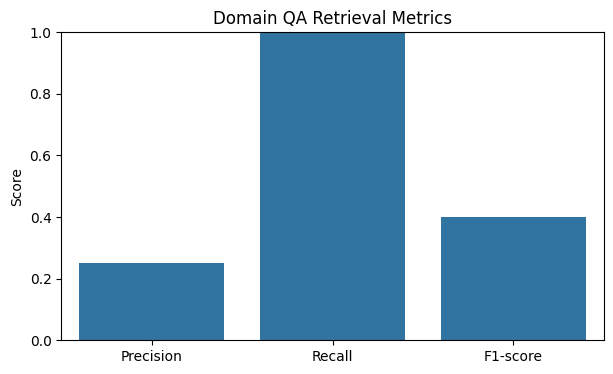

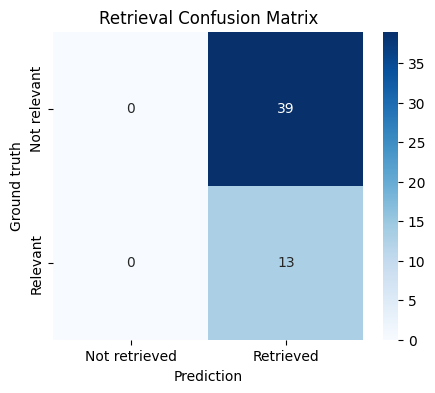

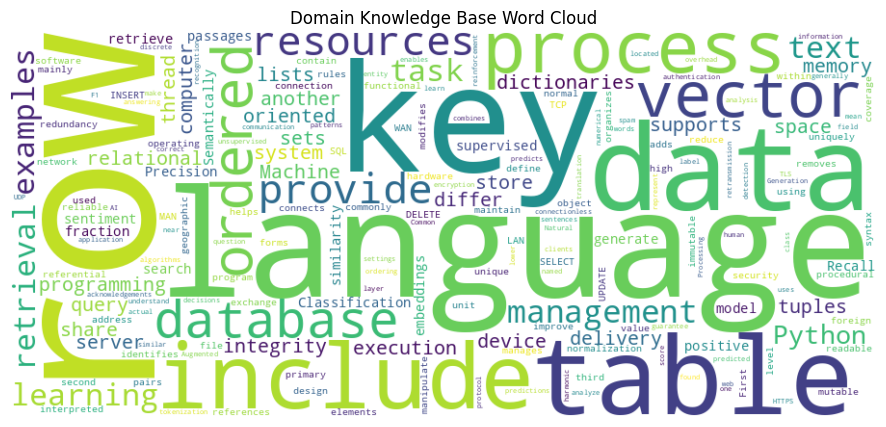

In [ ]:
names = ["Precision","Recall","F1-score"]
values = [precision, recall, f1]
plt.figure(figsize=(7,4))
sns.barplot(x=names, y=values)
plt.ylim(0,1); plt.title("Domain QA Retrieval Metrics"); plt.ylabel("Score")
plt.show()

cm = confusion_matrix(yt, yp, labels=[0,1])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not retrieved","Retrieved"],
            yticklabels=["Not relevant","Relevant"])
plt.title("Retrieval Confusion Matrix"); plt.xlabel("Prediction"); plt.ylabel("Ground truth")
plt.show()

# Fixed: Using the 'texts' list defined in the embedding cell instead of 'cleaned'
all_text = " ".join(texts)
wc = WordCloud(width=900, height=400, background_color="white").generate(all_text)
plt.figure(figsize=(12,5)); plt.imshow(wc, interpolation="bilinear")
plt.axis("off"); plt.title("Domain Knowledge Base Word Cloud"); plt.show()

In [ ]:
import gradio as gr
def chat_fn(message, history):
    reply, docs = answer_question(message)
    return reply + "\\n\\nSources: " + ", ".join(d["id"] for d in docs)

app = gr.ChatInterface(
    fn=chat_fn,
    title="Domain-Specific Question Answering Using RAG",
    description="Ask questions about Python, databases, operating systems, networks, ML and NLP."
)
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://76a137c29e351dd2d8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
